In [1]:
%load_ext autoreload

%autoreload 2

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from bgflow.utils import (assert_numpy, distance_vectors, distances_from_vectors, 
                          remove_mean, IndexBatchIterator, LossReporter, as_numpy, compute_distances
)
from bgflow import (GaussianMCMCSampler, DiffEqFlow, BoltzmannGenerator, Energy, Sampler, 
                    MultiDoubleWellPotential, MeanFreeNormalDistribution, KernelDynamics, 
                    BlackBoxDynamics, TimeIndependentDynamics, DenseNet)
from bgflow.bg import sampling_efficiency
import ot as pot
import tqdm
from eq_ot_flow.models import EGNN_dynamics
from eq_ot_flow.utilities import superpose_points, superpose_points_batch, plot_flowpath_trajectory, plot_flowpath_trajectory_3d
from eq_ot_flow.estimator import BruteForceEstimatorFast
from eq_ot_flow.LJ import LennardJonesPotential
from scipy.optimize import linear_sum_assignment
from torchdyn.core import NeuralODE


In [6]:
# first define system dimensionality and a target energy/distribution

dim = 165
n_particles = 55
n_dimensions = dim // n_particles


target = LennardJonesPotential(dim, n_particles, eps=1., rm=1, oscillator_scale=1, two_event_dims=False)

In [7]:
data_load = np.load("data/all_data_LJ55-1000.npy", allow_pickle=True)
data = torch.from_numpy(remove_mean(data_load, n_particles, n_dimensions))

n_training_data = 100000
np.random.seed(42)
idx = np.random.choice(np.arange(len(data)), len(data), replace=False)
data_smaller = data[idx[:n_training_data]]


In [8]:
holdout_start = 500000
assert holdout_start > n_training_data
data_holdout = data[idx[holdout_start:]]

In [14]:
# now set up a prior
prior =  MeanFreeNormalDistribution(dim, n_particles, two_event_dims=False).cuda()
prior_cpu =  MeanFreeNormalDistribution(dim, n_particles, two_event_dims=False)

In [20]:
# Build the Boltzmann Generator

net_dynamics = EGNN_dynamics(n_particles=n_particles, device='cuda',  n_dimension=dim // n_particles, hidden_nf=64,
    act_fn=torch.nn.SiLU(), n_layers=7, recurrent=True, tanh=True, attention=True, condition_time=True, mode='egnn_dynamics', agg='sum')


bb_dynamics = BlackBoxDynamics(
    dynamics_function=net_dynamics,
    divergence_estimator=BruteForceEstimatorFast()
)
flow = DiffEqFlow(
    dynamics=bb_dynamics
)
# having a flow and a prior, we can now define a Boltzmann Generator

bg = BoltzmannGenerator(prior, flow, target).cuda()

In [22]:
# train with convex mixture of NLL and KL loss

n_batch = 256
batch_iter = IndexBatchIterator(len(data_smaller), n_batch)

optim = torch.optim.Adam(bg.parameters(), lr=5e-4)

n_epochs = 600
n_report_steps = 5

reporter = LossReporter("NLL")


In [1]:
# start at 5e-4 for 600
# 5e-5 for 400


## Note, in practice the batch reordering should not be done during training

In [21]:
sigma = 0.01
for epoch in range(n_epochs):
    for it, idxs in enumerate(batch_iter):

        optim.zero_grad()
        x1 = data_smaller[idxs]#.cuda()
        batchsize = x1.shape[0]
        t = torch.rand(batchsize, 1).cuda()
        x0 = prior_cpu.sample(batchsize)
        # Resample x0, x1 according to transport matrix
        a1, b1 = pot.unif(x0.size()[0]), pot.unif(x1.size()[0])
        #M = torch.cdist(x0, x1) ** 2
        M = torch.zeros(batchsize, batchsize)
        for i in range(batchsize):
            points2_reordered = []
            points1 = x0[i].reshape(n_particles, n_dimensions)#.cpu()

            for j in range(batchsize):
                # define two sets of points
                points2 = x1[j].reshape(n_particles, n_dimensions)#.cpu()

                # compute pairwise distances between the two sets of points
                distances = torch.cdist(points1, points2)

                # use the Hungarian algorithm to solve the assignment problem
                row_idx, col_idx = linear_sum_assignment(distances**2)

                # reorder the second set of points according to the optimal assignment
                points2_reordered.append(points2[col_idx].unsqueeze(0))

            superposed_points2 = superpose_points_batch(torch.cat(points2_reordered, dim=0), reference=points1)
            M[i] = torch.cdist(points1.reshape(1, -1), superposed_points2.reshape(batchsize, -1))[0]

        M = M**2
        M = M / M.max()
        pi = pot.emd(a1, b1, M.detach().cpu().numpy())
        # Sample random interpolations on pi
        p = pi.flatten()
        p = p / p.sum()
        choices = np.random.choice(pi.shape[0] * pi.shape[1], p=p, size=batchsize)
        i, j = np.divmod(choices, pi.shape[1])
        x0 = x0[i]
        x1 = x1[j]
        # Hungarian algorithm
        for i in range(batchsize):
            # define two sets of points
            points1 = x0[i].reshape(n_particles, n_dimensions)#.cpu()
            points2 = x1[i].reshape(n_particles, n_dimensions)#.cpu()

            # compute pairwise distances between the two sets of points
            distances = torch.cdist(points1, points2)

            # use the Hungarian algorithm to solve the assignment problem
            row_idx, col_idx = linear_sum_assignment(distances**2)

            # reorder the second set of points according to the optimal assignment
            x1[i] = superpose_points(x1[i].reshape(n_particles, n_dimensions)[col_idx],
                                     x0[i].reshape(n_particles, n_dimensions)).flatten()
        x0 = x0.cuda()
        x1 = x1.cuda()
        mu_t = t * x1 + (1 - t) * x0
        sigma_t = sigma
        noise = prior.sample(batchsize)
        x = mu_t + sigma_t * noise
        ut = x1 - x0
        vt = bg.flow._dynamics._dynamics._dynamics_function(t, x)
        loss = torch.mean((vt - ut) ** 2)
        loss.backward()
        optim.step()
        reporter.report(loss)
        if it % n_report_steps == 0:
            print("\repoch: {0}, iter: {1}/{2}, loss: {3:.4}".format(
                    epoch,
                    it,
                    len(batch_iter),
                    *reporter.recent(1).ravel()
                ), end="")


In [ ]:
# eq OT
# PATH = "models/LJ55_eq_OT_flow_matching"

# OT
# PATH = "models/LJ55_OT_flow_matching"

# checkpoint = torch.load(PATH)
# flow.load_state_dict(checkpoint['model_state_dict']), optim.load_state_dict(checkpoint['optimizer_state_dict'])

In [28]:
bg.flow._integrator_atol = 1e-5
bg.flow._integrator_rtol = 1e-5

#use DTO
flow._use_checkpoints = True

# Anode options
options={
    "Nt": 20,
    "method": "RK4"
}
flow._kwargs = options

In [ ]:
# samples with or without weights

sample_with_dlogp = True

import tqdm
from torchdyn.core import NeuralODE
node = NeuralODE(
   net_dynamics, solver="dopri5", sensitivity="adjoint", atol=1e-4, rtol=1e-4
)

n_samples = 100
n_sample_batches = 50
latent_np = np.empty(shape=(0))
samples_np = np.empty(shape=(0))
log_w_np = np.empty(shape=(0))

energies_np = np.empty(shape=(0))
distances_x_np = np.empty(shape=(0))

if sample_with_dlogp:
    for i in tqdm.tqdm(range(n_sample_batches)):
        with torch.no_grad():
            samples, latent, dlogp = bg.sample(n_samples, with_latent=True, with_dlogp=True)
            log_weights = bg.log_weights_given_latent(samples, latent, dlogp, normalize=False).detach().cpu().numpy()
            latent_np = np.append(latent_np, latent.detach().cpu().numpy())
            samples_np = np.append(samples_np, samples.detach().cpu().numpy())
            distances_x = distances_from_vectors(distance_vectors(samples.view(-1, n_particles, n_dimensions))).detach().cpu().numpy().reshape(-1)
            distances_x_np = np.append(distances_x_np, distances_x)

            log_w_np = np.append(log_w_np, log_weights)
            energies = target.energy(samples).detach().cpu().numpy()
            energies_np = np.append(energies_np, energies)

else:
    for i in tqdm.tqdm(range(n_sample_batches)):
        with torch.no_grad():
            traj = node.trajectory(
                prior.sample(n_samples),
                t_span=torch.linspace(0, 1, 2),
            )
            latent = traj[0].reshape(-1, dim)
            samples = traj[-1].reshape(-1, dim)

            latent_np = np.append(latent_np, latent.detach().cpu().numpy())
            samples_np = np.append(samples_np, samples.detach().cpu().numpy())
            distances_x = distances_from_vectors(distance_vectors(samples.view(-1, n_particles, n_dimensions))).detach().cpu().numpy().reshape(-1)
            distances_x_np = np.append(distances_x_np, distances_x)

            energies = target.energy(samples).detach().cpu().numpy()
            energies_np = np.append(energies_np, energies)


latent_np = latent_np.reshape(-1, dim)
samples_np = samples_np.reshape(-1, dim)


In [ ]:
sampling_efficiency(torch.from_numpy(log_w_np)).item()

In [ ]:
energies_data = target.energy(data_holdout[::7]).numpy()
energies_bg = energies_np
min_energy = min(energies_data.min(), energies_bg.min())
max_energy = max(energies_data.max(), energies_bg.max())

plt.figure(figsize=(13,8))
efac = 1

plt.hist(energies_data, bins=100, density=True, range=(min_energy, -200), alpha=0.4, 
         label="MCMC data");
plt.hist(energies_bg, bins=100, density=True,  range=(min_energy, -200), alpha=0.4, 
 label="Boltzmann generator");


if sample_with_dlogp:
    plt.hist(energies_bg, bins=20, density=True,  range=(min_energy, -280), alpha=0.4, histtype='step', linewidth=4,
         color="r", label="BG weighted samples", weights=np.exp(log_w_np));
    
plt.xlabel(r"Energy / $k_B T$", fontsize=45)  
plt.xticks(fontsize=25) 
plt.yticks(fontsize=25);
plt.legend(fontsize=30);
plt.title("Energy distribution", fontsize=45);


In [41]:
import tqdm

class _Structure(torch.nn.Module):
    
    def __init__(self, structure):
        super().__init__()
        self._structure = torch.nn.Parameter(structure)
    
    def forward(self):
        self._structure
    
    @property
    def structure(self):
        return self._structure

def minimize_structure(energy, structure, n_iter=1000, lr=5e-3):
    structure = structure.clone()
    s = _Structure(structure).to(structure)
    optim = torch.optim.Adam(s.parameters(), lr=lr)
    for i in tqdm.tqdm(range(n_iter)):
        optim.zero_grad()
        loss = energy(s.structure)
        loss.sum().backward()
        optim.step()
    return loss, s.structure.data

loss, x_minimized = minimize_structure(target._energy, torch.from_numpy(samples_np)[::10], n_iter=1000)


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [27:11<00:00,  1.63s/it]


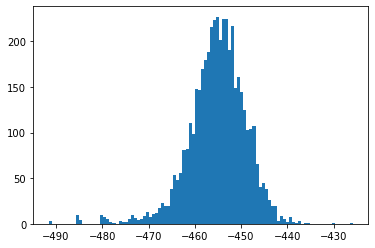

In [42]:
plt.hist(loss.flatten().cpu().detach(), bins=100);

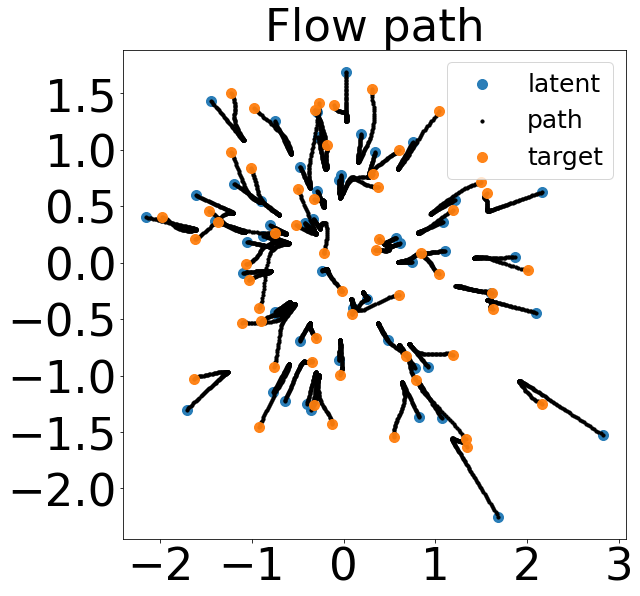

In [30]:
node = NeuralODE(
   net_dynamics, solver="dopri5", sensitivity="adjoint", atol=1e-4, rtol=1e-4
)

with torch.no_grad():
    traj = node.trajectory(
        prior.sample(100),
        t_span=torch.linspace(0, 1, 100),
    )
plot_flowpath_trajectory(traj[:, 0].reshape(-1, n_particles, n_dimensions)[:,:, :2])

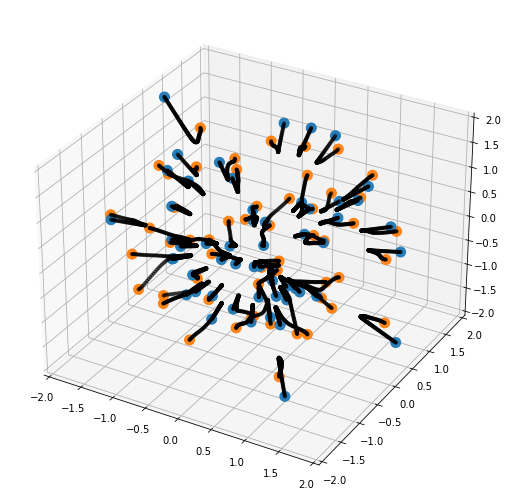

In [96]:
plot_flowpath_trajectory_3d(traj[:,1].reshape(-1, n_particles, n_dimensions))

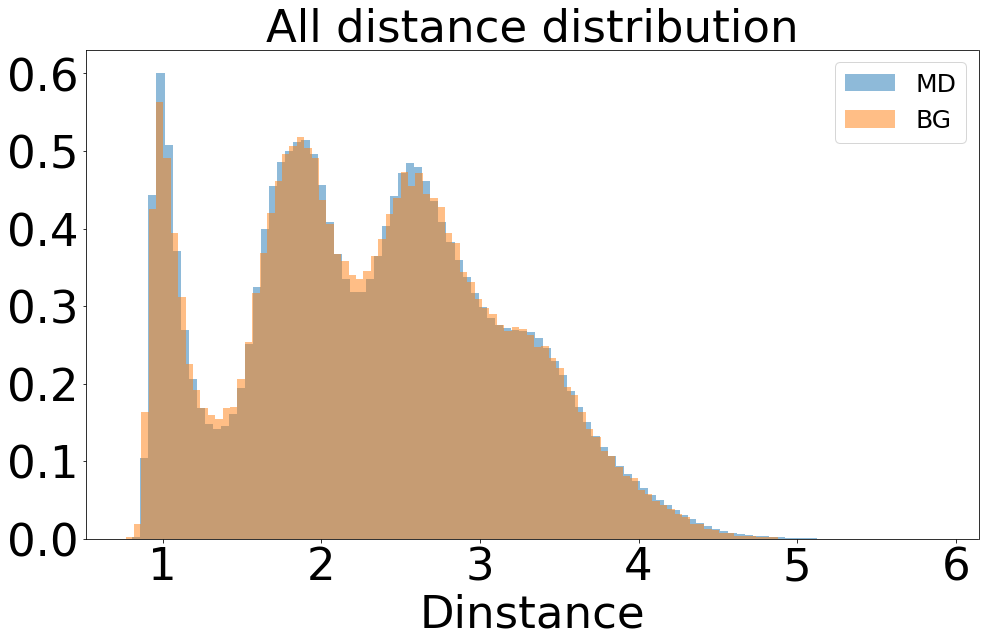

In [98]:
dists = as_numpy(compute_distances(traj[-1], n_particles, n_dimensions))
dists_data_holdout = as_numpy(compute_distances(data_holdout, n_particles, n_dimensions))

plt.figure(figsize=(16,9))
plt.hist(dists_data_holdout.reshape(-1), bins=100, density=True, alpha=0.5, label="MD");
plt.hist(dists.reshape(-1), bins=100, density=True, alpha=0.5, label="BG");
plt.legend(fontsize=25)
plt.xlabel("Dinstance", fontsize=45)  
plt.xticks(fontsize=45) 
plt.yticks(fontsize=45);
plt.title("All distance distribution", fontsize=45);

In [ ]:
path_lengths = torch.linalg.norm(traj[1:]-traj[:-1], dim=-1).sum(0) #/ len(t_span)
ot_path_lengths = []
for i in range(len(traj[-1])):
    # define two sets of points
    points1 = traj[0, i].reshape(n_particles, n_dimensions).cpu()
    points2 = traj[-1, i].reshape(n_particles, n_dimensions).cpu()

    # compute pairwise distances between the two sets of points
    distances = torch.cdist(points1, points2)

    # use the Hungarian algorithm to solve the assignment problem
    row_idx, col_idx = linear_sum_assignment(distances**2)
    #print((points2[col_idx]-points2).sum())
    # reorder the second set of points according to the optimal assignment
    points2 = superpose_points(points2[col_idx], points1).flatten()
    # reorder the second set of points according to the optimal assignment
    ot_path_lengths.append(np.linalg.norm(points2-points1.flatten()))
ot_path_lengths = np.array(ot_path_lengths)

x1 = data[:len(traj[-1])].cuda()
batchsize = x1.shape[0]
t = torch.rand(batchsize, 1).cuda()
x0 = prior.sample(batchsize)

# Resample x0, x1 according to transport matrix
a1, b1 = pot.unif(x0.size()[0]), pot.unif(x1.size()[0])
M = torch.cdist(x0, x1) ** 2
M = M / M.max()
pi = pot.emd(a1, b1, M.detach().cpu().numpy())
# Sample random interpolations on pi
p = pi.flatten()
p = p / p.sum()
choices = np.random.choice(pi.shape[0] * pi.shape[1], p=p, size=batchsize)
i, j = np.divmod(choices, pi.shape[1])
x0 = x0[i]
x1 = x1[j]
training_path_lengths = as_numpy(torch.linalg.norm(x1-x0, dim=-1))


plt.figure(figsize=(16,9))
plt.hist(as_numpy(ot_path_lengths), bins=100, alpha=0.5, label="OT path lengths");
#plt.hist(as_numpy(training_path_lengths), bins=100, alpha=0.5,label="Training path lengths");
plt.hist(as_numpy(path_lengths), bins=100, alpha=0.5,label="BG path lengths");

plt.xlabel("Path length", fontsize=45)  
plt.title(f"LJ55 - Path lengths", fontsize=45)
plt.legend(fontsize=25)
plt.xticks(fontsize=25) 
plt.yticks(fontsize=25);
as_numpy(path_lengths).mean(), as_numpy(ot_path_lengths).mean()


In [27]:
# reference dopri5
flow._use_checkpoints = False
bg.flow._integrator_atol = 1e-5
bg.flow._integrator_rtol = 1e-5
with torch.no_grad():

    samples, latent, dlogp = bg.sample(100, with_latent=True, with_dlogp=True)


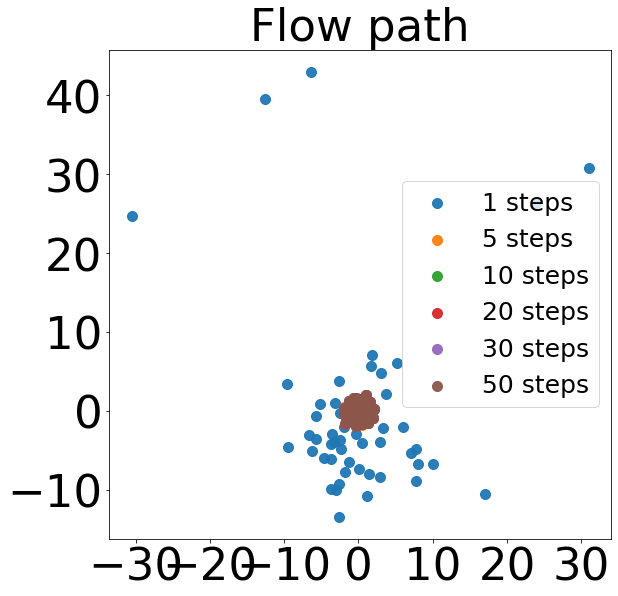

In [28]:

#rk4
flow._use_checkpoints = True
# Anode options

n_timesteps = [1,5,10,20,30, 50]
#start = time.time()
traj_list = []
dlogp_list = []

for t in n_timesteps:
    options={
    "Nt": t,
    "method": "RK4"
    }
    flow._kwargs = options

    with torch.no_grad():
        samples2, dlogp2 = bg.flow(latent)

        traj_list.append(samples2)
        dlogp_list.append(dlogp2)

plt.figure(figsize=(9,9))
plt.title("Flow path", fontsize=45);
plt.xticks(fontsize=45) 
plt.yticks(fontsize=45);
for t, traj in zip(n_timesteps, traj_list):
    target_sample = as_numpy(traj[5].reshape(-1, n_particles, n_dimensions)[:,:, :2][-1].reshape(-1, n_dimensions-1))
    plt.scatter(*target_sample.T, alpha=0.95, label=f"{t} steps",s=100)
plt.legend( fontsize=25);


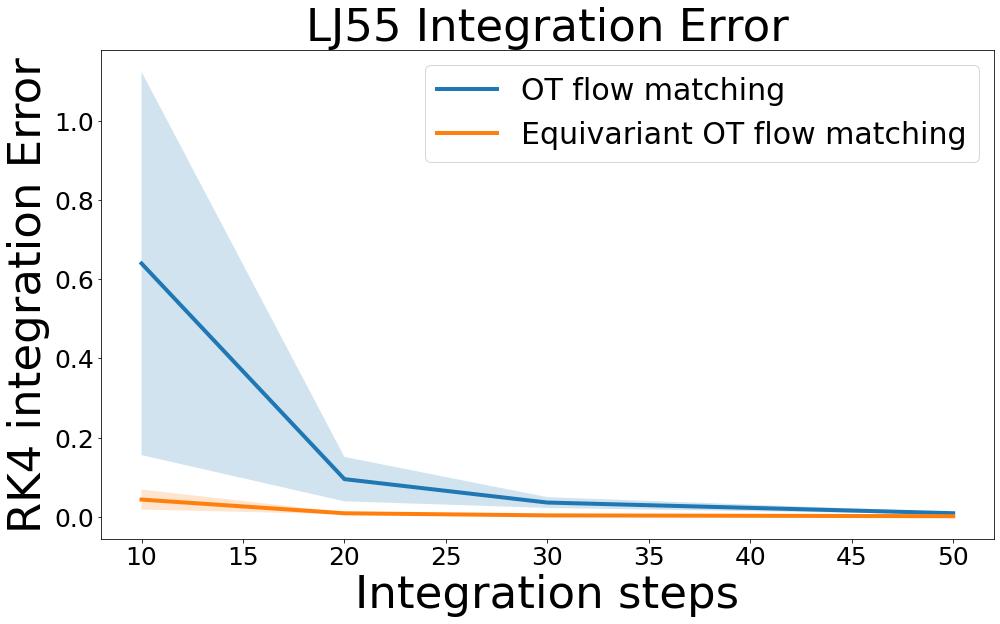

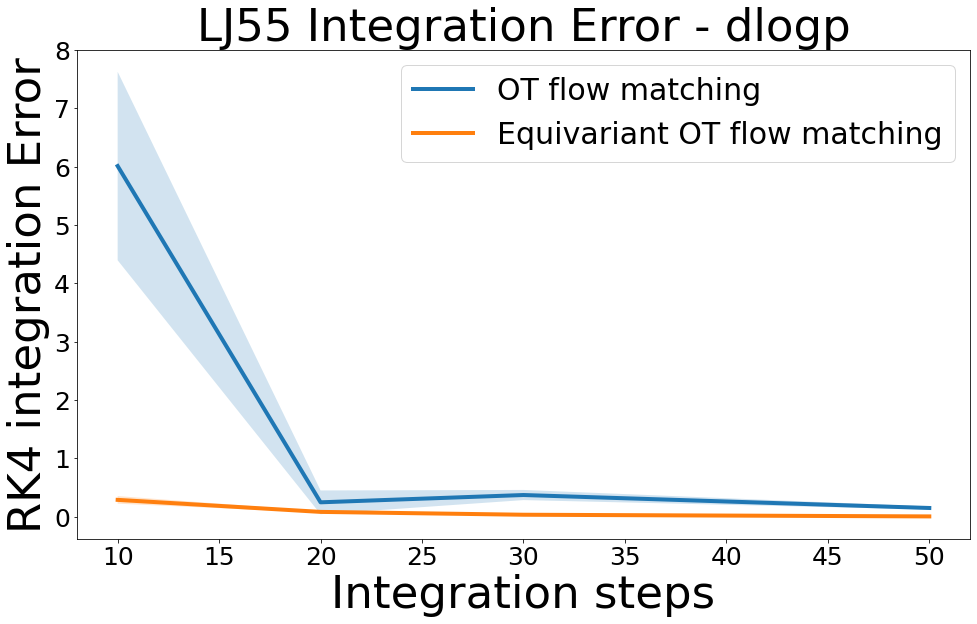

In [104]:

offset = 2
def plot_deviations(ax, times, data, label=None):
    means = np.mean(data, axis=-1)
    stds = np.std(data, axis=-1)

    ax.plot(times, means, linewidth=4, label=label)
    ax.fill_between(times, means - stds, means + stds, alpha=0.2)
    

fig, ax = plt.subplots(figsize=(16,9))
differences = []
for t, traj in zip(n_timesteps, traj_list):
    differences.append(as_numpy(torch.abs(samples - traj).sum(-1)))
differences = np.array(differences)
plot_deviations(ax, n_timesteps[offset:], differences[offset:], label="Equivariant OT flow matching")

plt.xticks(fontsize=25) 
plt.yticks(fontsize=25);
plt.legend(fontsize=30);
ax.set_title("LJ55 Integration Error", fontsize=45)
ax.set_xlabel("Integration steps", fontsize=45)
ax.set_ylabel("RK4 integration Error", fontsize=45)


fig, ax = plt.subplots(figsize=(16,9))
differences = []
for t, dlogp_rk4 in zip(n_timesteps, dlogp_list):
    differences.append(as_numpy(torch.abs(dlogp - dlogp_rk4)))
differences = np.array(differences).squeeze(-1)
plot_deviations(ax, n_timesteps[offset:], differences[offset:], label="Equivariant OT flow matching")

plt.xticks(fontsize=25) 
plt.yticks(fontsize=25);
plt.legend(fontsize=30);
ax.set_title("LJ55 Integration Error - dlogp", fontsize=45)
ax.set_xlabel("Integration steps", fontsize=45)
ax.set_ylabel("RK4 integration Error", fontsize=45)



In [ ]:
import tqdm
data_holdout = data_holdout
batch_size=50
spacing = 100
n = len(data_holdout) // batch_size // spacing
nll = 0

for i in tqdm.tqdm(range(6,n)):
    batch = data_holdout[::spacing][i*batch_size:i*batch_size+ batch_size].cuda()
    with torch.no_grad():
        nll += bg.energy(batch).mean() / n

nll

In [ ]:
import tqdm
batch_size=50
spacing = 30
n = len(data_smaller) // batch_size// spacing
nll_data_smaller = 0

for i in tqdm.tqdm(range(n)):
    batch = data_smaller[::spacing][i*batch_size:i*batch_size+ batch_size].cuda()
    with torch.no_grad():
        nll_data_smaller += bg.energy(batch).mean() / n

nll_data_smaller